In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
results = pd.read_csv("ppo_eval_results_20episode.csv")
print(results.head())

      agent  episode  seed  reward  episode_length
0  baseline        1   350     3.0           12452
1  baseline        2   351     0.0           21703
2  baseline        3   352     0.0           18111
3  baseline        4   353     2.0           18241
4  baseline        5   354     0.0           38296


<function matplotlib.pyplot.show(close=None, block=None)>

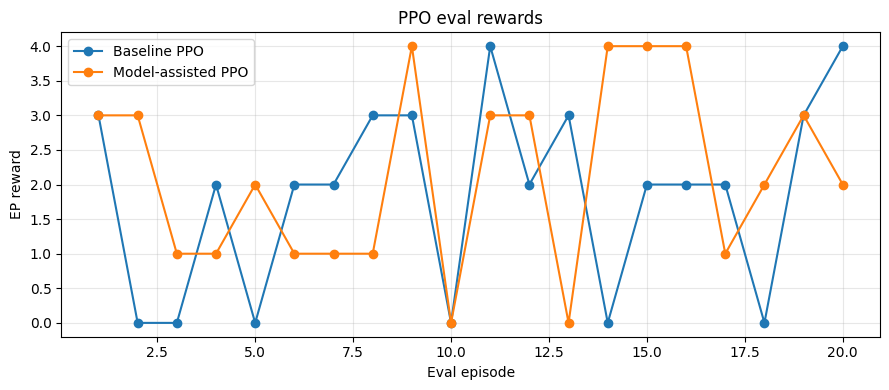

In [8]:
#comparing reward
base = results[results["agent"]=="baseline"]
model_ass = results[results["agent"]=="model_assisted"]

plt.figure(figsize=(9,4))
plt.plot(base["episode"], base["reward"], marker="o", label="Baseline PPO")
plt.plot(model_ass["episode"], model_ass["reward"],marker="o", label="Model-assisted PPO")

plt.xlabel("Eval episode")
plt.ylabel("EP reward")
plt.title("PPO eval rewards")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("ppo_ep_rewards.png", dpi = 300)
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

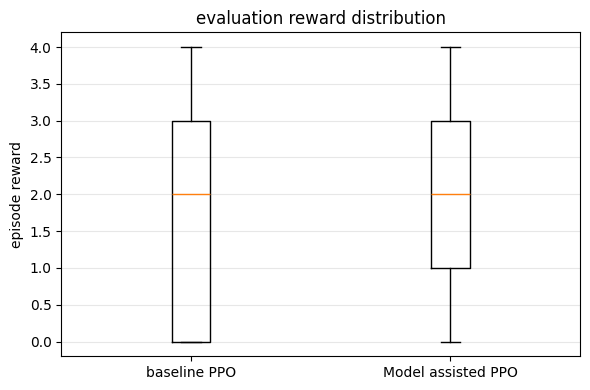

In [9]:
#reward distribution comparison
plt.figure(figsize=(6,4))
plt.boxplot([base["reward"], model_ass["reward"]], tick_labels=["baseline PPO", "Model assisted PPO"])
plt.ylabel("episode reward")
plt.title("evaluation reward distribution")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("ppo_reward_dis.png", dpi=300)
plt.show

In [11]:
#statistics from the results
print("baseline PPO")
print("Mean reward:", base["reward"].mean())
print("Standard deviation", base["reward"].std())
print()
print("model assisted ppo")
print("mean reward:", model_ass["reward"].mean())
print("standard deviation:", model_ass["reward"].std())




baseline PPO
Mean reward: 1.85
Standard deviation 1.3869694338832115

model assisted ppo
mean reward: 2.15
standard deviation: 1.3484884325167863


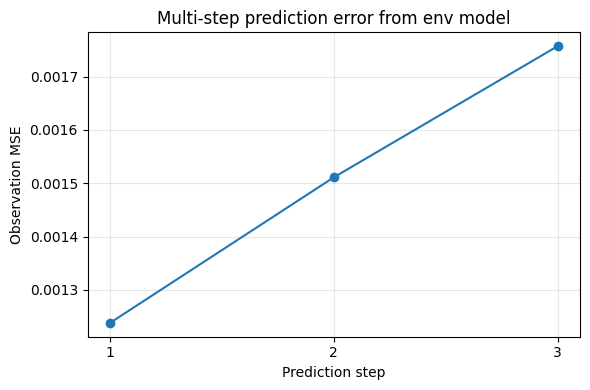

In [ ]:
#showcasing rollout error 
steps = [1,2,3]
observation_mse = [0.001238, 0.001511, 0.001757]
plt.figure(figsize=(6,4))
plt.plot(steps, observation_mse, marker="o")
plt.xlabel("Prediction step")
plt.ylabel("Observation MSE")
plt.title("The observation prediction error across model rollout steps")
plt.xticks(steps)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("model_rollout_error.png", dpi=300)
plt.show()